<a href="https://colab.research.google.com/github/brooklynnsudler-collab/Brooklynn_INFO4670_Fall2026/blob/main/Sudler_Assignment3_AssociationRuleMining_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (11569 transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt


## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import networkx as nx

## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [57]:
df = pd.read_csv("bread_basket.csv")
df.dtypes

,0
transaction,int64
item,object
date_time,object
time,object
period_day,object
weekday_weekend,object


### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [58]:
print(df.describe(include='all'))

         transaction    item   date_time   time period_day weekday_weekend
count   20507.000000   20507       20507  20507      20507           20507
unique           NaN      94         159   1255          4               2
top              NaN  Coffee  2017-02-04  11:06  afternoon         weekday
freq             NaN    5471         292     52      11569           12807
mean     4976.202370     NaN         NaN    NaN        NaN             NaN
std      2796.203001     NaN         NaN    NaN        NaN             NaN
min         1.000000     NaN         NaN    NaN        NaN             NaN
25%      2552.000000     NaN         NaN    NaN        NaN             NaN
50%      5137.000000     NaN         NaN    NaN        NaN             NaN
75%      7357.000000     NaN         NaN    NaN        NaN             NaN
max      9684.000000     NaN         NaN    NaN        NaN             NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

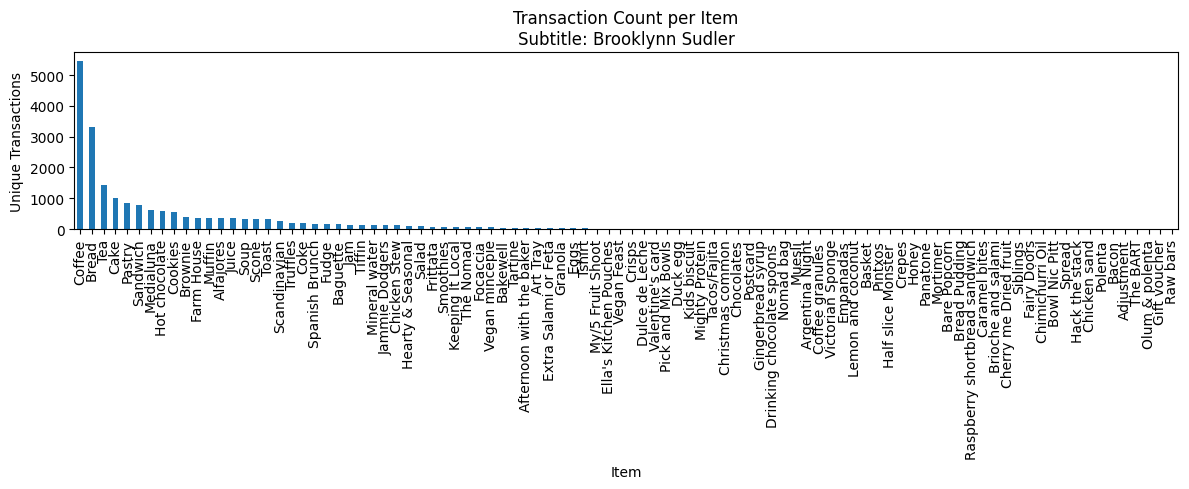

In [59]:
# c) Bar plot of transaction counts per item
subtitle = "Brooklynn Sudler"  # <-- EDIT THIS
item_counts = df['item'].value_counts().sort_values(ascending=False)

ax = item_counts.plot(kind='bar', figsize=(12,5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item"); plt.ylabel("Unique Transactions")
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [60]:
print("Coffee:", item_counts["Coffee"])
print("Tea:", item_counts["Tea"])
print("Alfajores:", item_counts["Alfajores"])
print("Juice:", item_counts["Juice"])
print("Chicken Stew:", item_counts["Chicken Stew"])

Coffee: 5471
Tea: 1435
Alfajores: 369
Juice: 369
Chicken Stew: 123


## 3) Frequent Itemset Mining with FP‑Growth (min_support = 0.02) (20 pts)
We pivot the data to a **transaction × item** one‑hot table (boolean), then run FP‑Growth.

In [61]:
basket = pd.crosstab(df['transaction'], df['item']).astype(bool)

frequent_itemsets = fpgrowth(
    basket,
    min_support=0.02,
    use_colnames=True
)

frequent_itemsets

,support,itemsets
0,0.327205,(Bread)
1,0.029054,(Scandinavian)
2,0.058320,(Hot chocolate)
3,0.054411,(Cookies)
4,0.038457,(Muffin)
5,0.478394,(Coffee)
6,0.086107,(Pastry)
7,0.061807,(Medialuna)
8,0.142631,(Tea)
9,0.039197,(Farm House)


## 4) Association Rules + Report Table (30 pts)
(metric = confidence, min_threshold = ?) Please find a suitable min_threshold

In [62]:
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.50
)

rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Hot chocolate),(Coffee),0.058320,0.478394,0.029583,0.507246,1.060311,1.0,0.001683,1.058553,0.060403,0.058333,0.055314,0.284542
1,(Cookies),(Coffee),0.054411,0.478394,0.028209,0.518447,1.083723,1.0,0.002179,1.083174,0.081700,0.055905,0.076787,0.288707
2,(Pastry),(Coffee),0.086107,0.478394,0.047544,0.552147,1.154168,1.0,0.006351,1.164682,0.146161,0.091968,0.141396,0.325764
3,(Medialuna),(Coffee),0.061807,0.478394,0.035182,0.569231,1.189878,1.0,0.005614,1.210871,0.170091,0.069665,0.174148,0.321387
4,(Juice),(Coffee),0.038563,0.478394,0.020602,0.534247,1.116750,1.0,0.002154,1.119919,0.108738,0.041507,0.107078,0.288656
5,(Cake),(Coffee),0.103856,0.478394,0.054728,0.526958,1.101515,1.0,0.005044,1.102664,0.102840,0.103745,0.093105,0.320679
6,(Sandwich),(Coffee),0.071844,0.478394,0.038246,0.532353,1.112792,1.0,0.003877,1.115384,0.109205,0.074701,0.103448,0.306150
7,(Toast),(Coffee),0.033597,0.478394,0.023666,0.704403,1.472431,1.0,0.007593,1.764582,0.332006,0.048464,0.433293,0.376936


## 5) Interpretation (10 pts)
**Interpret the rule `{Coffee, Cake} ⇒ {Bread}` in plain English.**

- **Support**: What fraction of *all* transactions contain Coffee, Cake, and Bread together?
- **Confidence**: Among baskets with Coffee and Cake, what share also include Bread?
- **Lift > 1** implies positive association; comment on practical meaning.

{Coffee, Cake} => {Bread} is a rule that indicates that someone that buys Coffee and Cake is very likely to also buy Bread. The support is 0.01 meaning 1% of all transactions containing Coffee and Cake also contain Bread. The lift is 0.56, which indicates a negative association because the lift is less than 1. This implys that Coffee and Cake purchases are not associated with a higher chance of Bread also being purchased.

In [63]:
triple_count = (basket['Coffee'] & basket['Cake'] & basket['Bread']).sum()
coffee_cake_count = (basket['Coffee'] & basket['Cake']).sum()

support = triple_count / len(basket)
confidence = triple_count / coffee_cake_count

bread_support = basket['Bread'].mean()
lift = confidence / bread_support

print("Support:", support)
print("Confidence:", confidence)
print("Lift:", lift)

Support: 0.010036978341257264
Confidence: 0.1833976833976834
Lift: 0.5604969562024777
